# Poda por cosseno no GraphPFN com o protocolo do artigo

Este notebook repete a poda por Block Influence (cosseno) dos notebooks `poda_cosseno_k_menores_graphpfn.ipynb` e `poda_cosseno_k_menores_sem_camada0_graphpfn.ipynb`, agora com **os datasets e o protocolo de avaliação do artigo do GraphPFN** (Eremeev et al., arXiv 2509.21489, Seção 5.1 e Apêndice D).

$$BI_{\cos}(l) = 1 - \cos(h_l^{in}, h_l^{out})$$

Duas versões de poda são comparadas com o **modelo inteiro** (12 camadas):

| Versão | Camadas removidas em "poda k menores" |
|---|---|
| **Livre** | as *k* camadas de menor BI (k = 2 … 11) |
| **Camada 0 protegida** | as *k* camadas de menor BI entre as camadas 1–11 (k = 2 … 11) |

### Protocolo (igual ao artigo)

| Item | Artigo | Aqui |
|---|---|---|
| Datasets GraphLand | artnet-exp, city-reviews, tolokers-2, artnet-views, avazu-ctr, city-roads-M, hm-prices, twitch-views | os mesmos |
| Datasets clássicos | amazon-ratings, facebook, pubmed, questions, wiki-cs | os mesmos |
| Split GraphLand | RL (*Random Low*) oficial | o mesmo |
| Split clássicos | aleatório 10% / 10% / 80% | aleatório 10% / 10% / 80% (semente 0, fixo) |
| PCA | 64 dims só em amazon-ratings e questions; **sem PCA** no pubmed | o mesmo |
| Métrica | AP (binária), acurácia (multiclasse), R² (regressão) | a mesma (+ ROC-AUC, F1-macro, MAE, RMSE como secundárias) |
| Regime | ICL com ensemble de 10 membros | o mesmo |
| Repetições | 10 | **3 sementes** (custo: cada avaliação são 10 forwards; o desvio entre execuções no artigo é ≤ 0,01) |

**Diferenças inevitáveis, registradas aqui:**
- **facebook:** a versão de 128 features do PyG (`FacebookPagePage`) é baixada de um domínio fora do ar (graphmining.ai). Usa-se o mesmo grafo e rótulos do repositório original MUSAE (22.470 nós, 4 classes), com as features esparsas binárias reduzidas a 128 dimensões por TruncatedSVD.
- **GPU de 16 GB** (o artigo usou uma A100 de 80 GB): a Seção 1 descreve como a inferência é feita em blocos, com resultado idêntico. Datasets que mesmo assim não cabem são listados e saem da análise.

## 0. Configuração

In [1]:
import os, sys, json, time, warnings
os.environ.setdefault("PYTORCH_CUDA_ALLOC_CONF", "expandable_segments:True")
from pathlib import Path
from contextlib import contextmanager

cwd = Path.cwd().resolve()
PROJECT_ROOT = cwd if (cwd / "src" / "graphpfn").exists() else cwd / "GraphFPN"
os.chdir(PROJECT_ROOT)  # LimiXWrapper procura ./checkpoints/LimiX-16M.ckpt
sys.path.insert(0, str(PROJECT_ROOT / "src"))
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import scipy.sparse as sp
import torch
import torch.nn as nn
import torch.nn.functional as F
import dgl
import matplotlib.pyplot as plt
from sklearn.decomposition import TruncatedSVD
from sklearn.metrics import f1_score, mean_squared_error
from IPython.display import display

from graphpfn import GraphDataset, GraphPFN, GraphPFNLight
from graphpfn.inference.preprocessing import prepare_features_tensor, prepare_graph, standardize_targets
from graphpfn.inference.util import apply_model, compute_metrics

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
CHECKPOINT = PROJECT_ROOT / "checkpoints" / "graphpfn-adapters-1_3.pt"
GRAPHLAND_ROOT = Path.home() / ".cache" / "graphland"
PYG_ROOT = Path.home() / ".cache" / "pyg_data"
RESULTS_DIR = PROJECT_ROOT.parent / "Block_Influence_results" / "graphfpn_poda_cosseno_artigo"
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

# Datasets na ordem das Tabelas 1 e 2 do artigo. d_pca segue o Apêndice D.
DATASETS = {
    "artnet-exp":     dict(source="graphland"),
    "city-reviews":   dict(source="graphland"),
    "tolokers-2":     dict(source="graphland"),
    "artnet-views":   dict(source="graphland"),
    "avazu-ctr":      dict(source="graphland"),
    "city-roads-M":   dict(source="graphland"),
    "hm-prices":      dict(source="graphland"),
    "twitch-views":   dict(source="graphland"),
    "amazon-ratings": dict(source="classic", d_pca=64),
    "facebook":       dict(source="classic"),
    "pubmed":         dict(source="classic"),
    "questions":      dict(source="classic", d_pca=64),
    "wiki-cs":        dict(source="classic"),
}
# GraphPFN (ICL) com ensemble, Tabelas 1 e 2 do artigo (escala 0–1)
PAPER_ICL = {"artnet-exp": .5179, "city-reviews": .8025, "tolokers-2": .6129, "artnet-views": .6279,
             "avazu-ctr": .3163, "city-roads-M": .6485, "hm-prices": .7788, "twitch-views": .7320,
             "amazon-ratings": .4494, "facebook": .9242, "pubmed": .9050, "questions": .2138, "wiki-cs": .8201}

N_MEMBERS = 10           # ensemble do artigo
SEEDS = [0, 1, 2]
N_LAYERS = 12
K_LIST = list(range(2, N_LAYERS))
VARIANTS = {"Livre": set(), "Camada 0 protegida": {0}}
BI_COL = "cos_all"       # BI sobre todos os tokens (ShortGPT)
AMP = True

PRIMARY_METRIC = {"binclass": "average_precision", "multiclass": "accuracy", "regression": "r2"}
METRICS = {"binclass": ["average_precision", "roc_auc"],
           "multiclass": ["accuracy", "f1_macro"],
           "regression": ["r2", "mae", "rmse"]}
LOWER_IS_BETTER = {"mae", "rmse"}
METRIC_LABEL = {"roc_auc": "ROC-AUC", "average_precision": "AP", "accuracy": "Acurácia",
                "f1_macro": "F1-macro", "r2": "R²", "mae": "MAE", "rmse": "RMSE"}

COLORS = ["#2a78d6", "#eb6834"]
GRAY = "#52514e"
plt.rcParams.update({
    "figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.alpha": 0.25, "axes.titleweight": "bold",
    "lines.linewidth": 2, "lines.markersize": 5, "font.size": 10,
})
print(f"Dispositivo: {DEVICE} ({torch.cuda.get_device_name() if DEVICE.type == 'cuda' else 'cpu'}, "
      f"{torch.cuda.get_device_properties(0).total_memory / 2**30:.0f} GB)")
print(f"Resultados:  {RESULTS_DIR}")

Dispositivo: cuda (NVIDIA GeForce RTX 5060 Ti, 15 GB)
Resultados:  /home/isabelly/Documentos/Graph_Pruning/Block_Influence_results/graphfpn_poda_cosseno_artigo


## 1. Inferência em blocos para caber em 16 GB

O GraphPFN processa o grafo inteiro de uma vez, como um tensor `[1, nós, tokens, 192]`. Em vários datasets do artigo isso passa de 16 GB. As operações abaixo são **independentes** ao longo de uma dimensão, então podem ser feitas em blocos sem mudar o resultado:

| Operação | Independente ao longo de |
|---|---|
| Atenção entre features (LimiX) | nós |
| Atenção entre amostras (LimiX) | posições de token (features) |
| MLPs (LimiX) e encoder de features | tokens / nós |
| Adaptadores de grafo (atenção nas arestas + MLP) | posições de token |

Além disso, o `feature_decoder` é desligado. Ele só reconstrói features para a perda auxiliar MGM do pré-treino e não participa da predição, mas era o maior pico de memória.

A célula seguinte confere a equivalência: compara o forward original com o forward em blocos no tolokers-2.

In [2]:
import torch.utils.checkpoint
from graphpfn._vendor.limix.model.layer import MLP, MultiheadAttention
from graphpfn.model.layers import GraphPFNResidualModule
from graphpfn._vendor.limix.model.encoders import MaskEmbEncoder

CHUNK_BUDGET = 2**26  # elementos por bloco de computação


def _ck(fn, *args):
    """No treino (com gradiente), cada bloco é recalculado no backward em vez de guardar suas ativações."""
    if torch.is_grad_enabled():
        return torch.utils.checkpoint.checkpoint(fn, *args, use_reentrant=False)
    return fn(*args)


def _wrap_attention(orig):
    """Atenção de features ([1, nós, tokens, E]) e de amostras ([1, tokens, nós, E]): independente ao longo da dim 1."""
    def forward(x, x_kv=None, copy_first_head_kv=False, attn_mask=None,
                calculate_sample_attention=False, calculate_feature_attention=False):
        if attn_mask is not None or calculate_sample_attention or calculate_feature_attention:
            return orig(x, x_kv, copy_first_head_kv, attn_mask, calculate_sample_attention, calculate_feature_attention)
        per_slice = max(x.shape[2], x_kv.shape[2] if x_kv is not None else 0) * x.shape[3] * 4
        step = max(1, CHUNK_BUDGET // per_slice)
        att = lambda a, b: orig(a, b, copy_first_head_kv)[0]
        out = torch.cat([_ck(att, x[:, i:i + step], None if x_kv is None else x_kv[:, i:i + step])
                         for i in range(0, x.shape[1], step)], dim=1)
        return out, None, None
    return forward


def _wrap_mlp(orig, hidden):
    """MLP atua token a token."""
    def forward(x):
        flat = x.reshape(-1, x.shape[-1])
        step = max(1, CHUNK_BUDGET // hidden)
        return torch.cat([_ck(orig, flat[i:i + step]) for i in range(0, flat.shape[0], step)]).reshape(*x.shape[:-1], -1)
    return forward


def _wrap_graph_residual(orig):
    """Adaptadores de grafo (atenção nas arestas e MLP): independentes por posição de token."""
    def forward(graph, x):
        n_tokens = x.shape[2]
        per_token = max(graph.num_edges() * 4 * 3, x.shape[1] * x.shape[3] * 6)
        step = max(1, CHUNK_BUDGET // per_token)
        if step >= n_tokens:
            return _ck(lambda a: orig(graph, a), x)
        return torch.cat([_ck(lambda a: orig(graph, a), x[:, :, i:i + step].contiguous())
                          for i in range(0, n_tokens, step)], dim=2)
    return forward


def _wrap_feature_encoder(orig, out_key):
    """Encoder de features: cada valor vira um embedding sem olhar os outros nós."""
    def forward(inp):
        n = inp["data"].shape[1]
        step = max(1, CHUNK_BUDGET // (inp["data"].shape[2] * 192 * 6))
        keys = [k for k, v in inp.items() if torch.is_tensor(v) and v.ndim >= 2 and v.shape[1] == n]
        rest = {k: v for k, v in inp.items() if k not in keys}

        def run(*tensors):
            return orig({**rest, **dict(zip(keys, tensors))})[out_key]
        out = dict(inp)  # não altera o dicionário de entrada (o recálculo do checkpoint o reutiliza)
        out[out_key] = torch.cat([_ck(run, *[inp[k][:, i:i + step] for k in keys])
                                  for i in range(0, n, step)], dim=1)
        return out
    return forward


def enable_low_memory(model):
    """Processa em blocos as operações independentes por nó/token. Matematicamente idêntico ao forward original."""
    if getattr(model, "_low_memory", False):
        return model
    for m in model.modules():
        if isinstance(m, MultiheadAttention):
            m.forward = _wrap_attention(m.forward)
        elif isinstance(m, MLP):
            m.forward = _wrap_mlp(m.forward, m.mlp[0].out_features)
        elif isinstance(m, GraphPFNResidualModule):
            m.forward = _wrap_graph_residual(m.forward)
        elif isinstance(m, MaskEmbEncoder):
            m.forward = _wrap_feature_encoder(m.forward, m.out_key)
    # feature_decoder só alimenta a perda auxiliar de reconstrução de features (MGM, usada no pré-treino);
    # a predição sai de cls_y_decoder/reg_y_decoder. Na inferência ele é o pico de memória, então é desligado.
    model.tfm.module.feature_decoder.forward = lambda x: None
    model._low_memory = True
    return model


def load_base():
    base = GraphPFNLight()
    base.load_state_dict(torch.load(CHECKPOINT, map_location="cpu", weights_only=True)["state_dict"], strict=False)
    return base.eval().to(DEVICE)

BASE = load_base()
P_TOTAL = sum(p.numel() for p in BASE.parameters())
P_LAYER = sum(p.numel() for p in BASE.tfm.module.transformer_encoder.layers[0].parameters())

## 2. Dados

In [3]:
def random_split(n, seed=0):
    """Split aleatório 10/10/80 do artigo para os datasets clássicos."""
    perm = np.random.default_rng(seed).permutation(n)
    a, b = int(0.1 * n), int(0.2 * n)
    masks = {k: np.zeros(n, bool) for k in ["train", "val", "test"]}
    masks["train"][perm[:a]] = True
    masks["val"][perm[a:b]] = True
    masks["test"][perm[b:]] = True
    return masks

def load_classic(name):
    if name == "facebook":
        d = PYG_ROOT / "facebook_musae"   # MUSAE: edges.csv, features.csv (esparso), target.csv
        e, f = pd.read_csv(d / "edges.csv"), pd.read_csv(d / "features.csv")
        t = pd.read_csv(d / "target.csv").sort_values("id")
        n = len(t)
        X = sp.csr_matrix((f["value"], (f["node_id"], f["feature_id"])), shape=(n, f["feature_id"].max() + 1))
        x = TruncatedSVD(128, random_state=0).fit_transform(X).astype(np.float32)
        src, dst, y = e["id_1"].values, e["id_2"].values, t["target"].values
    else:
        from torch_geometric.datasets import HeterophilousGraphDataset, WikiCS, Planetoid
        g = {"amazon-ratings": lambda: HeterophilousGraphDataset(PYG_ROOT, "amazon-ratings"),
             "questions": lambda: HeterophilousGraphDataset(PYG_ROOT, "questions"),
             "wiki-cs": lambda: WikiCS(PYG_ROOT / "wiki-cs", is_undirected=True),
             "pubmed": lambda: Planetoid(PYG_ROOT, "PubMed")}[name]()[0]
        x, y, n = g.x.numpy().astype(np.float32), g.y.numpy(), g.num_nodes
        src, dst = g.edge_index.numpy()
    return GraphDataset(name=name, graph=dgl.graph((src, dst), num_nodes=n, idtype=torch.int32),
                        features={"other": x}, targets=y.astype(np.float32), masks=random_split(n),
                        task_type="binclass" if name == "questions" else "multiclass")

def prepare_task(name, cfg):
    """Replica o pré-processamento de graphpfn.inference.icl.predict_icl."""
    if cfg["source"] == "graphland":
        ds = GraphDataset.from_graphland(name, root_dir=GRAPHLAND_ROOT / name / name / "raw", split="RL")
    else:
        ds = load_classic(name)
    graph = prepare_graph(ds.graph).to(DEVICE)
    np.random.seed(0)  # o PCA do pacote usa SVD aleatorizado sem random_state
    features = prepare_features_tensor(ds.features, ds.masks["train"], d_pca=cfg.get("d_pca")).to(DEVICE)
    train_mask = torch.tensor(ds.masks["train"]).to(DEVICE)
    y_train = torch.tensor(ds.targets).to(DEVICE)[train_mask]
    stats = None
    if ds.task_type == "regression":
        y_train, stats = standardize_targets(y_train=y_train)
    else:
        y_train = y_train.long()
    y_te = ds.targets[ds.masks["test"]]
    chance = {"binclass": float(np.mean(y_te)),                                     # AP do acaso = taxa de positivos
              "multiclass": np.unique(y_te, return_counts=True)[1].max() / len(y_te),  # classe majoritária
              "regression": 0.0}[ds.task_type]
    return dict(name=name, ds=ds, task=ds.task_type, graph=graph, features=features, train_mask=train_mask,
                y_train=y_train, stats=stats, metric=PRIMARY_METRIC[ds.task_type], chance=chance)

def free_task(t):
    for k in ["graph", "features", "train_mask", "y_train"]:
        t.pop(k, None)
    torch.cuda.empty_cache()

### Funções de avaliação, poda e Block Influence

In [4]:
def get_layers(base):
    return base.tfm.module.transformer_encoder.layers

@contextmanager
def pruned(base, remove=()):
    """Remove camadas trocando a ModuleList (equivale a substituí-las pela identidade)."""
    stack = base.tfm.module.transformer_encoder
    full = stack.layers
    remove = set(int(i) for i in remove)
    stack.layers = nn.ModuleList([l for i, l in enumerate(full) if i not in remove])
    try:
        yield
    finally:
        stack.layers = full

def bi_reduce(h_in, h_out, eval_pos, chunk=4096):
    a, b = h_in[0], h_out[0]
    s_all = n_all = s_tgt = n_tgt = 0.0
    for s in range(0, a.shape[0], chunk):
        cos = F.cosine_similarity(a[s:s + chunk].float(), b[s:s + chunk].float(), dim=-1).clamp(-1, 1)
        s_all += (1 - cos).sum().item(); n_all += cos.numel()
        is_test = torch.arange(s, s + cos.shape[0], device=cos.device) >= eval_pos
        ct = cos[is_test, -1]
        s_tgt += (1 - ct).sum().item(); n_tgt += ct.numel()
    return np.array([s_all, n_all, s_tgt, n_tgt])

@torch.no_grad()
def predict(base, t, seed, n_members=N_MEMBERS, remove=(), collect_bi=False):
    """Um forward do ensemble. A semente fixa as permutações do ensemble e as features aleatórias,
    então todas as configurações de poda de uma mesma semente são comparadas de forma pareada."""
    torch.manual_seed(seed)
    model = GraphPFN(base, n_members=n_members, n_features=t["features"].shape[1], n_classes=t["ds"].n_classes,
                     device=DEVICE, verbose=False).eval()
    acc, hooks = {}, []
    if collect_bi:
        eval_pos = int(t["train_mask"].sum())
        for i, layer in enumerate(get_layers(base)):
            hooks.append(layer.register_forward_hook(
                lambda m, a, kw, out, i=i: acc.__setitem__(i, acc.get(i, 0) + bi_reduce(a[0], out[0], eval_pos)),
                with_kwargs=True))
    try:
        with pruned(base, remove):
            preds = apply_model(model=model, dataset=t["ds"], graph=t["graph"], features=t["features"],
                                y_train=t["y_train"], train_mask=t["train_mask"],
                                regression_target_stats=t["stats"], amp=AMP, device=DEVICE)
    finally:
        for h in hooks:
            h.remove()
    bi = {i: {"cos_all": v[0] / v[1], "cos_tgt": v[2] / max(v[3], 1)} for i, v in acc.items()}
    return preds, bi

def all_metrics(t, preds):
    out = {}
    for split in ["val", "test"]:
        m = t["ds"].masks[split]
        y, p = t["ds"].targets[m], preds[m]
        r = compute_metrics(y_true=y, y_pred=p, task_type=t["task"])
        if t["task"] == "multiclass":
            r["f1_macro"] = f1_score(y, p.argmax(-1), average="macro")
        elif t["task"] == "regression":
            r["rmse"] = float(np.sqrt(mean_squared_error(y, p)))
        out.update({f"{split}_{k}": v for k, v in r.items()})
    return out

def is_oom(e):
    """Falta de memória aparece como OutOfMemoryError (torch), DGLError (kernels do DGL) ou, quando o SDPA
    estoura, como o fallback do LimiX que exige flash-attention."""
    msg = str(e).lower()
    return isinstance(e, torch.OutOfMemoryError) or "out of memory" in msg or "flash attention is not supported" in msg

EVAL_COLS = ["dataset", "removidas", "seed"] + [f"{s}_{m}" for s in ["val", "test"] for m in
             ["average_precision", "roc_auc", "accuracy", "f1_macro", "r2", "mae", "rmse"]]

def append_rows(path, rows, cols=None):
    """Acrescenta linhas ao CSV. `cols` fixa o esquema (as métricas mudam com o tipo de tarefa)."""
    df = pd.DataFrame(rows) if cols is None else pd.DataFrame(rows).reindex(columns=cols)
    df.to_csv(path, mode="a", header=not path.exists(), index=False)

### Verificação: inferência em blocos = inferência original

Compara, no tolokers-2 (que cabe nos dois modos), as predições do modelo original e do modelo com inferência em blocos.

In [5]:
_t = prepare_task("tolokers-2", DATASETS["tolokers-2"])
_ref = load_base()
p_orig, _ = predict(_ref, _t, seed=0, n_members=1)
enable_low_memory(BASE)
p_low, _ = predict(BASE, _t, seed=0, n_members=1)
print(f"Maior diferença absoluta entre as predições: {np.abs(p_orig - p_low).max():.2e}")
assert np.allclose(p_orig, p_low, atol=1e-5)
del _ref, _t, p_orig, p_low
torch.cuda.empty_cache()

Maior diferença absoluta entre as predições: 0.00e+00


## 3. Execução: modelo inteiro + BI + poda (livre e com a camada 0 protegida)

Para cada dataset:
1. **Modelo inteiro**, 3 sementes. No mesmo forward, *hooks* medem o BI cosseno de cada camada (média sobre os 10 membros do ensemble e as 3 sementes).
2. **Ordem de poda** por BI crescente, nas duas versões.
3. **Modelos podados**, 3 sementes. Configurações iguais nas duas versões (por exemplo, quando a camada 0 ainda não entrou na lista) são avaliadas uma vez só.

Cada avaliação é gravada em `avaliacoes.csv` assim que termina. Se a execução for interrompida, ela continua de onde parou. Datasets que não cabem na GPU ficam registrados em `sem_memoria.csv`.

In [6]:
EVAL_CSV, BI_CSV, OOM_CSV = RESULTS_DIR / "avaliacoes.csv", RESULTS_DIR / "block_influence.csv", RESULTS_DIR / "sem_memoria.csv"

def key(remove):
    return str(sorted(int(i) for i in remove))

def done_set():
    if not EVAL_CSV.exists():
        return set()
    d = pd.read_csv(EVAL_CSV)
    return set(zip(d.dataset, d.removidas, d.seed))

def orders_for(name):
    b = pd.read_csv(BI_CSV)
    b = b[b.dataset == name].groupby("layer")[BI_COL].mean().sort_values()
    return {v: [l for l in b.index.tolist() if l not in prot] for v, prot in VARIANTS.items()}

META = {}
oom = set(pd.read_csv(OOM_CSV)["dataset"]) if OOM_CSV.exists() else set()
tic_all = time.time()
for name, cfg in DATASETS.items():
    if name in oom:
        print(f"⚠ {name}: sem memória de GPU (registrado antes)")
        continue
    t = prepare_task(name, cfg)
    META[name] = dict(task=t["task"], metric=t["metric"], chance=t["chance"], n_nodes=t["ds"].n_nodes,
                      n_edges=t["graph"].num_edges(), n_features=t["features"].shape[1],
                      n_train=int(t["ds"].masks["train"].sum()), n_test=int(t["ds"].masks["test"].sum()))
    tic = time.time()
    try:
        done = done_set()
        for seed in SEEDS:                                   # 1) inteiro + BI
            if (name, "[]", seed) in done:
                continue
            preds, bi = predict(BASE, t, seed, collect_bi=True)
            append_rows(BI_CSV, [dict(dataset=name, seed=seed, layer=i, **v) for i, v in bi.items()])
            append_rows(EVAL_CSV, [dict(dataset=name, removidas="[]", seed=seed, **all_metrics(t, preds))], EVAL_COLS)
        orders = orders_for(name)                            # 2) ordens de poda
        configs = {key(o[:k]) for o in orders.values() for k in K_LIST}
        done = done_set()
        for seed in SEEDS:                                   # 3) podados
            for rem in sorted(configs, key=len):
                if (name, rem, seed) in done:
                    continue
                preds, _ = predict(BASE, t, seed, remove=json.loads(rem))
                append_rows(EVAL_CSV, [dict(dataset=name, removidas=rem, seed=seed, **all_metrics(t, preds))], EVAL_COLS)
        print(f"✓ {name:15s} {time.time() - tic:7.0f}s")
    except Exception as e:
        if not is_oom(e):
            raise
        print(f"⚠ {name}: sem memória de GPU, removido da análise")
        append_rows(OOM_CSV, [dict(dataset=name, n_nodes=t["ds"].n_nodes, n_features=t["features"].shape[1],
                                   n_edges=t["graph"].num_edges())])
        META.pop(name, None)
    finally:
        free_task(t)
print(f"Total: {(time.time() - tic_all) / 60:.0f} min")

✓ artnet-exp            0s
⚠ city-reviews: sem memória de GPU (registrado antes)


✓ tolokers-2            0s


✓ artnet-views          0s
⚠ avazu-ctr: sem memória de GPU (registrado antes)


✓ city-roads-M          0s


✓ hm-prices          4713s


...

✓ amazon-ratings     1057s


✓ facebook           1882s


⚠ pubmed: sem memória de GPU, removido da análise


✓ questions          2368s


✓ wiki-cs            2577s
Total: 266 min


### Datasets avaliados e modelo inteiro × artigo

In [7]:
df_eval = pd.read_csv(EVAL_CSV)
df_bi = pd.read_csv(BI_CSV)
TASKS = [n for n in DATASETS if n in META]

if OOM_CSV.exists():
    display(pd.read_csv(OOM_CSV).style.hide(axis="index")
            .set_caption("Fora da análise: não cabem na GPU de 16 GB mesmo com inferência em blocos"))

full = df_eval[df_eval.removidas == "[]"]
display(pd.DataFrame([{
    "Dataset": n, "Tarefa": META[n]["task"], "Nós": META[n]["n_nodes"], "Arestas (sim.)": META[n]["n_edges"],
    "Features": META[n]["n_features"], "Treino": META[n]["n_train"], "Teste": META[n]["n_test"],
    "Métrica": METRIC_LABEL[META[n]["metric"]], "Acaso": round(META[n]["chance"], 4),
    "Inteiro (aqui)": f"{full[full.dataset == n]['test_' + META[n]['metric']].mean():.4f} "
                      f"± {full[full.dataset == n]['test_' + META[n]['metric']].std():.4f}",
    "Artigo, GraphPFN (ICL)": PAPER_ICL[n],
} for n in TASKS]).style.hide(axis="index").set_caption("Modelo inteiro: reprodução do artigo (Tabelas 1 e 2)"))

dataset,n_nodes,n_features,n_edges
city-reviews,148801,34,2330830
avazu-ctr,76269,229,21968154
pubmed,19717,500,88648


Dataset,Tarefa,Nós,Arestas (sim.),Features,Treino,Teste,Métrica,Acaso,Inteiro (aqui),"Artigo, GraphPFN (ICL)"
artnet-exp,binclass,50405,560696,74,5040,40324,AP,0.100000,0.5189 ± 0.0008,0.517900
tolokers-2,binclass,11758,1038000,16,1175,9407,AP,0.218200,0.6125 ± 0.0027,0.612900
artnet-views,regression,50405,560696,50,5040,40324,R²,0.000000,0.6286 ± 0.0006,0.627900
city-roads-M,regression,57073,214208,20,3610,28886,R²,0.000000,0.6491 ± 0.0001,0.648500
hm-prices,regression,46563,21461990,41,4656,37251,R²,0.000000,0.7797 ± 0.0005,0.778800
twitch-views,regression,168114,13595114,4,16811,134492,R²,0.000000,0.7325 ± 0.0009,0.732000
amazon-ratings,multiclass,24492,186100,64,2449,19594,Acurácia,0.368600,0.4385 ± 0.0005,0.449400
facebook,multiclass,22470,341646,128,2247,17976,Acurácia,0.306100,0.9114 ± 0.0015,0.924200
questions,binclass,48921,307080,64,4892,39137,AP,0.030000,0.2083 ± 0.0005,0.213800
wiki-cs,multiclass,11701,431206,300,1170,9361,Acurácia,0.229600,0.8210 ± 0.0008,0.820100


## 4. Block Influence (cosseno) e ordem de poda

In [8]:
bi = df_bi.groupby(["dataset", "layer"], sort=False)[["cos_all", "cos_tgt"]].mean().reset_index()
display(bi.pivot(index="layer", columns="dataset", values=BI_COL)[TASKS]
        .style.background_gradient(cmap="Blues", axis=0).format("{:.4f}")
        .set_caption(f"BI cosseno por camada ({BI_COL}); mais claro = menor BI = podada primeiro"))

ORDERS = {n: orders_for(n) for n in TASKS}
for v in VARIANTS:
    display(pd.DataFrame({n: [str(sorted(ORDERS[n][v][:k])) for k in K_LIST] for n in TASKS},
                         index=pd.Index(K_LIST, name="k")).style.set_caption(f"Camadas removidas em cada k: {v}"))

dataset,artnet-exp,tolokers-2,artnet-views,city-roads-M,hm-prices,twitch-views,amazon-ratings,facebook,questions,wiki-cs
layer,,,,,,,,,,
0,0.1231,0.1693,0.1276,0.1728,0.1245,0.1867,0.1310,0.1336,0.1419,0.1138
1,0.0228,0.0464,0.0134,0.0183,0.0142,0.0166,0.0236,0.0188,0.0235,0.0148
2,0.0501,0.0524,0.0496,0.0505,0.0492,0.0470,0.0602,0.0615,0.0611,0.0615
3,0.1105,0.1162,0.1063,0.1094,0.1242,0.1105,0.1423,0.1437,0.1479,0.1453
4,0.1151,0.0987,0.1075,0.1266,0.1049,0.1113,0.0939,0.0995,0.1098,0.1007
5,0.2868,0.2644,0.2794,0.2756,0.3008,0.3043,0.2844,0.2921,0.2985,0.2710
6,0.3345,0.3238,0.3489,0.3272,0.3233,0.2997,0.3539,0.3529,0.3425,0.3404
7,0.2396,0.2139,0.2257,0.2317,0.2369,0.2193,0.2230,0.2334,0.2484,0.2336
8,0.3738,0.3252,0.3654,0.3293,0.3590,0.3136,0.3572,0.3576,0.3762,0.3309


,artnet-exp,tolokers-2,artnet-views,city-roads-M,hm-prices,twitch-views,amazon-ratings,facebook,questions,wiki-cs
k,,,,,,,,,,
2,"[1, 2]","[1, 2]","[1, 2]","[1, 2]","[1, 2]","[1, 2]","[1, 2]","[1, 2]","[1, 2]","[1, 2]"
3,"[1, 2, 3]","[1, 2, 4]","[1, 2, 3]","[1, 2, 3]","[1, 2, 4]","[1, 2, 3]","[1, 2, 4]","[1, 2, 4]","[1, 2, 4]","[1, 2, 4]"
4,"[1, 2, 3, 4]","[1, 2, 3, 4]","[1, 2, 3, 4]","[1, 2, 3, 4]","[1, 2, 3, 4]","[1, 2, 3, 4]","[0, 1, 2, 4]","[0, 1, 2, 4]","[0, 1, 2, 4]","[0, 1, 2, 4]"
5,"[0, 1, 2, 3, 4]","[1, 2, 3, 4, 10]","[0, 1, 2, 3, 4]","[0, 1, 2, 3, 4]","[0, 1, 2, 3, 4]","[1, 2, 3, 4, 10]","[0, 1, 2, 3, 4]","[0, 1, 2, 3, 4]","[0, 1, 2, 3, 4]","[0, 1, 2, 3, 4]"
6,"[0, 1, 2, 3, 4, 7]","[0, 1, 2, 3, 4, 10]","[0, 1, 2, 3, 4, 7]","[0, 1, 2, 3, 4, 7]","[0, 1, 2, 3, 4, 10]","[0, 1, 2, 3, 4, 10]","[0, 1, 2, 3, 4, 7]","[0, 1, 2, 3, 4, 7]","[0, 1, 2, 3, 4, 7]","[0, 1, 2, 3, 4, 7]"
7,"[0, 1, 2, 3, 4, 7, 10]","[0, 1, 2, 3, 4, 7, 10]","[0, 1, 2, 3, 4, 7, 10]","[0, 1, 2, 3, 4, 7, 10]","[0, 1, 2, 3, 4, 7, 10]","[0, 1, 2, 3, 4, 7, 10]","[0, 1, 2, 3, 4, 7, 10]","[0, 1, 2, 3, 4, 7, 10]","[0, 1, 2, 3, 4, 7, 10]","[0, 1, 2, 3, 4, 7, 10]"
8,"[0, 1, 2, 3, 4, 5, 7, 10]","[0, 1, 2, 3, 4, 5, 7, 10]","[0, 1, 2, 3, 4, 5, 7, 10]","[0, 1, 2, 3, 4, 5, 7, 10]","[0, 1, 2, 3, 4, 5, 7, 10]","[0, 1, 2, 3, 4, 6, 7, 10]","[0, 1, 2, 3, 4, 5, 7, 10]","[0, 1, 2, 3, 4, 5, 7, 10]","[0, 1, 2, 3, 4, 5, 7, 10]","[0, 1, 2, 3, 4, 5, 7, 10]"
9,"[0, 1, 2, 3, 4, 5, 6, 7, 10]","[0, 1, 2, 3, 4, 5, 6, 7, 10]","[0, 1, 2, 3, 4, 5, 6, 7, 10]","[0, 1, 2, 3, 4, 5, 6, 7, 10]","[0, 1, 2, 3, 4, 5, 6, 7, 10]","[0, 1, 2, 3, 4, 5, 6, 7, 10]","[0, 1, 2, 3, 4, 5, 6, 7, 10]","[0, 1, 2, 3, 4, 5, 6, 7, 10]","[0, 1, 2, 3, 4, 5, 6, 7, 10]","[0, 1, 2, 3, 4, 5, 7, 8, 10]"
10,"[0, 1, 2, 3, 4, 5, 6, 7, 8, 10]","[0, 1, 2, 3, 4, 5, 6, 7, 8, 10]","[0, 1, 2, 3, 4, 5, 6, 7, 8, 10]","[0, 1, 2, 3, 4, 5, 6, 7, 8, 10]","[0, 1, 2, 3, 4, 5, 6, 7, 8, 10]","[0, 1, 2, 3, 4, 5, 6, 7, 8, 10]","[0, 1, 2, 3, 4, 5, 6, 7, 8, 10]","[0, 1, 2, 3, 4, 5, 6, 7, 8, 10]","[0, 1, 2, 3, 4, 5, 6, 7, 8, 10]","[0, 1, 2, 3, 4, 5, 6, 7, 8, 10]"


,artnet-exp,tolokers-2,artnet-views,city-roads-M,hm-prices,twitch-views,amazon-ratings,facebook,questions,wiki-cs
k,,,,,,,,,,
2,"[1, 2]","[1, 2]","[1, 2]","[1, 2]","[1, 2]","[1, 2]","[1, 2]","[1, 2]","[1, 2]","[1, 2]"
3,"[1, 2, 3]","[1, 2, 4]","[1, 2, 3]","[1, 2, 3]","[1, 2, 4]","[1, 2, 3]","[1, 2, 4]","[1, 2, 4]","[1, 2, 4]","[1, 2, 4]"
4,"[1, 2, 3, 4]","[1, 2, 3, 4]","[1, 2, 3, 4]","[1, 2, 3, 4]","[1, 2, 3, 4]","[1, 2, 3, 4]","[1, 2, 3, 4]","[1, 2, 3, 4]","[1, 2, 3, 4]","[1, 2, 3, 4]"
5,"[1, 2, 3, 4, 7]","[1, 2, 3, 4, 10]","[1, 2, 3, 4, 7]","[1, 2, 3, 4, 7]","[1, 2, 3, 4, 10]","[1, 2, 3, 4, 10]","[1, 2, 3, 4, 7]","[1, 2, 3, 4, 7]","[1, 2, 3, 4, 7]","[1, 2, 3, 4, 7]"
6,"[1, 2, 3, 4, 7, 10]","[1, 2, 3, 4, 7, 10]","[1, 2, 3, 4, 7, 10]","[1, 2, 3, 4, 7, 10]","[1, 2, 3, 4, 7, 10]","[1, 2, 3, 4, 7, 10]","[1, 2, 3, 4, 7, 10]","[1, 2, 3, 4, 7, 10]","[1, 2, 3, 4, 7, 10]","[1, 2, 3, 4, 7, 10]"
7,"[1, 2, 3, 4, 5, 7, 10]","[1, 2, 3, 4, 5, 7, 10]","[1, 2, 3, 4, 5, 7, 10]","[1, 2, 3, 4, 5, 7, 10]","[1, 2, 3, 4, 5, 7, 10]","[1, 2, 3, 4, 6, 7, 10]","[1, 2, 3, 4, 5, 7, 10]","[1, 2, 3, 4, 5, 7, 10]","[1, 2, 3, 4, 5, 7, 10]","[1, 2, 3, 4, 5, 7, 10]"
8,"[1, 2, 3, 4, 5, 6, 7, 10]","[1, 2, 3, 4, 5, 6, 7, 10]","[1, 2, 3, 4, 5, 6, 7, 10]","[1, 2, 3, 4, 5, 6, 7, 10]","[1, 2, 3, 4, 5, 6, 7, 10]","[1, 2, 3, 4, 5, 6, 7, 10]","[1, 2, 3, 4, 5, 6, 7, 10]","[1, 2, 3, 4, 5, 6, 7, 10]","[1, 2, 3, 4, 5, 6, 7, 10]","[1, 2, 3, 4, 5, 7, 8, 10]"
9,"[1, 2, 3, 4, 5, 6, 7, 8, 10]","[1, 2, 3, 4, 5, 6, 7, 8, 10]","[1, 2, 3, 4, 5, 6, 7, 8, 10]","[1, 2, 3, 4, 5, 6, 7, 8, 10]","[1, 2, 3, 4, 5, 6, 7, 8, 10]","[1, 2, 3, 4, 5, 6, 7, 8, 10]","[1, 2, 3, 4, 5, 6, 7, 8, 10]","[1, 2, 3, 4, 5, 6, 7, 8, 10]","[1, 2, 3, 4, 5, 6, 7, 8, 10]","[1, 2, 3, 4, 5, 6, 7, 8, 10]"
10,"[1, 2, 3, 4, 5, 6, 7, 8, 9, 10]","[1, 2, 3, 4, 5, 6, 7, 8, 9, 10]","[1, 2, 3, 4, 5, 6, 7, 8, 9, 10]","[1, 2, 3, 4, 5, 6, 7, 8, 9, 10]","[1, 2, 3, 4, 5, 6, 7, 8, 9, 10]","[1, 2, 3, 4, 5, 6, 7, 8, 10, 11]","[1, 2, 3, 4, 5, 6, 7, 8, 9, 10]","[1, 2, 3, 4, 5, 6, 7, 8, 9, 10]","[1, 2, 3, 4, 5, 6, 7, 8, 9, 10]","[1, 2, 3, 4, 5, 6, 7, 8, 9, 10]"


## 5. Resultados: modelo inteiro × podado

Valores no **teste**, média ± desvio-padrão em 3 sementes. **Δ** é a diferença para o modelo inteiro na mesma métrica (para MAE/RMSE, Δ positivo = pior).

In [9]:
def results(name, variant):
    """Linhas: inteiro + k = 2..11 na versão escolhida."""
    d = df_eval[df_eval.dataset == name]
    rows = []
    for k in [0] + K_LIST:
        rem = key(ORDERS[name][variant][:k])
        r = d[d.removidas == rem]
        rows.append(dict(k=k, removidas=rem, **{c: r[c].mean() for c in d.columns if c.startswith("test_")},
                         **{c + "_std": r[c].std() for c in d.columns if c.startswith("test_")}))
    return pd.DataFrame(rows)

RES = {(n, v): results(n, v) for n in TASKS for v in VARIANTS}
long = pd.concat([r.assign(dataset=n, versao=v) for (n, v), r in RES.items()])
long.to_csv(RESULTS_DIR / "resultados_por_k.csv", index=False)

def table_for(name, variant):
    r = RES[(name, variant)]
    tab = pd.DataFrame({"Configuração": ["Inteiro (12 camadas)" if k == 0 else f"Poda {k} menores" for k in r.k],
                        "Camadas removidas": r.removidas.replace("[]", "—"),
                        "Parâmetros (M)": ((P_TOTAL - r.k * P_LAYER) / 1e6).round(2)})
    for m in METRICS[META[name]["task"]]:
        tab[METRIC_LABEL[m]] = [f"{a:.4f} ± {b:.4f}" for a, b in zip(r[f"test_{m}"], r[f"test_{m}_std"].fillna(0))]
        tab[f"Δ {METRIC_LABEL[m]}"] = r[f"test_{m}"] - r[f"test_{m}"].iloc[0]
    return tab

### 5.1 Resumo: métrica do artigo no teste

In [10]:
for v in VARIANTS:
    s = pd.DataFrame({f"{n} ({METRIC_LABEL[META[n]['metric']]})": RES[(n, v)][f"test_{META[n]['metric']}"].values
                      for n in TASKS}, index=["Inteiro"] + [f"Poda {k} menores" for k in K_LIST])
    s.to_csv(RESULTS_DIR / f"resumo_{'livre' if v == 'Livre' else 'camada0_protegida'}.csv")
    display(s.style.format("{:.4f}").set_caption(f"{v}: métrica do artigo no teste (linha 'Inteiro' = modelo completo)"))

,artnet-exp (AP),tolokers-2 (AP),artnet-views (R²),city-roads-M (R²),hm-prices (R²),twitch-views (R²),amazon-ratings (Acurácia),facebook (Acurácia),questions (AP),wiki-cs (Acurácia)
Inteiro,0.5189,0.6125,0.6286,0.6491,0.7797,0.7325,0.4385,0.9114,0.2083,0.8210
Poda 2 menores,0.3185,0.5216,0.5277,0.5961,0.6522,0.6427,0.3539,0.7784,0.0780,0.7743
Poda 3 menores,0.3684,0.4147,0.5286,0.5660,0.4027,0.4461,0.3917,0.7573,0.0594,0.6326
Poda 4 menores,0.1969,0.4590,0.3776,0.5192,0.3937,0.2088,0.0667,0.2430,0.0321,0.0669
Poda 5 menores,0.1026,0.3446,-0.4086,-0.5135,-0.4462,0.1196,0.2795,0.2836,0.0284,0.1070
Poda 6 menores,0.1162,0.2468,-0.2521,-0.1172,-0.3397,-0.2963,0.2072,0.2767,0.0378,0.0391
Poda 7 menores,0.1009,0.1762,-1.0325,-0.9938,-1.5360,-0.5949,0.1328,0.2429,0.0255,0.1623
Poda 8 menores,0.0999,0.2003,-1.7988,-1.0685,-1.7453,-0.1453,0.1328,0.2351,0.0239,0.1070
Poda 9 menores,0.1052,0.1902,-0.0554,-0.1421,-0.0001,-0.3159,0.2601,0.2415,0.0267,0.0700
Poda 10 menores,0.1296,0.1928,-0.0727,-0.0209,-0.0072,-0.0555,0.1337,0.1771,0.0374,0.1136


,artnet-exp (AP),tolokers-2 (AP),artnet-views (R²),city-roads-M (R²),hm-prices (R²),twitch-views (R²),amazon-ratings (Acurácia),facebook (Acurácia),questions (AP),wiki-cs (Acurácia)
Inteiro,0.5189,0.6125,0.6286,0.6491,0.7797,0.7325,0.4385,0.9114,0.2083,0.8210
Poda 2 menores,0.3185,0.5216,0.5277,0.5961,0.6522,0.6427,0.3539,0.7784,0.0780,0.7743
Poda 3 menores,0.3684,0.4147,0.5286,0.5660,0.4027,0.4461,0.3917,0.7573,0.0594,0.6326
Poda 4 menores,0.1969,0.4590,0.3776,0.5192,0.3937,0.2088,0.3858,0.7367,0.0597,0.6079
Poda 5 menores,0.1337,0.3446,0.2501,0.4534,0.1953,0.1196,0.3797,0.5975,0.0492,0.4490
Poda 6 menores,0.1104,0.3385,0.1942,0.4254,0.0405,0.0592,0.3631,0.4085,0.0421,0.2388
Poda 7 menores,0.1301,0.3343,-0.2264,0.0100,-0.0469,-0.0130,0.1358,0.2005,0.0354,0.2119
Poda 8 menores,0.1236,0.2942,-0.1168,-0.0721,-0.0270,-0.0811,0.2507,0.3124,0.0428,0.1144
Poda 9 menores,0.0902,0.2764,-0.5812,-0.5656,-0.4283,-0.5976,0.3006,0.2725,0.0339,0.0812
Poda 10 menores,0.0988,0.2225,-0.2041,-0.1524,-0.1540,-0.5422,0.2072,0.2725,0.0275,0.0869


### 5.2 Tabelas por dataset (todas as métricas)

In [11]:
for n in TASKS:
    for v in VARIANTS:
        tab = table_for(n, v)
        tab.to_csv(RESULTS_DIR / f"tabela_{n}_{'livre' if v == 'Livre' else 'camada0_protegida'}.csv", index=False)
        display(tab.style.format({c: "{:+.4f}" for c in tab.columns if c.startswith("Δ")}).hide(axis="index")
                .set_caption(f"{n} — {v} — acaso ({METRIC_LABEL[META[n]['metric']]}) = {META[n]['chance']:.3f}"))

Configuração,Camadas removidas,Parâmetros (M),AP,Δ AP,ROC-AUC,Δ ROC-AUC
Inteiro (12 camadas),—,20.090000,0.5189 ± 0.0008,+0.0000,0.8469 ± 0.0004,+0.0000
Poda 2 menores,"[1, 2]",16.840000,0.3185 ± 0.0034,-0.2004,0.7193 ± 0.0043,-0.1276
Poda 3 menores,"[1, 2, 3]",15.220000,0.3684 ± 0.0114,-0.1505,0.7848 ± 0.0025,-0.0621
Poda 4 menores,"[1, 2, 3, 4]",13.590000,0.1969 ± 0.0059,-0.3219,0.6609 ± 0.0040,-0.1860
Poda 5 menores,"[0, 1, 2, 3, 4]",11.970000,0.1026 ± 0.0005,-0.4163,0.5127 ± 0.0009,-0.3342
Poda 6 menores,"[0, 1, 2, 3, 4, 7]",10.350000,0.1162 ± 0.0029,-0.4027,0.5436 ± 0.0065,-0.3033
Poda 7 menores,"[0, 1, 2, 3, 4, 7, 10]",8.720000,0.1009 ± 0.0016,-0.4180,0.5153 ± 0.0084,-0.3316
Poda 8 menores,"[0, 1, 2, 3, 4, 5, 7, 10]",7.100000,0.0999 ± 0.0006,-0.4190,0.5031 ± 0.0018,-0.3438
Poda 9 menores,"[0, 1, 2, 3, 4, 5, 6, 7, 10]",5.470000,0.1052 ± 0.0026,-0.4137,0.5238 ± 0.0086,-0.3231
Poda 10 menores,"[0, 1, 2, 3, 4, 5, 6, 7, 8, 10]",3.850000,0.1296 ± 0.0018,-0.3893,0.5795 ± 0.0021,-0.2674


Configuração,Camadas removidas,Parâmetros (M),AP,Δ AP,ROC-AUC,Δ ROC-AUC
Inteiro (12 camadas),—,20.090000,0.5189 ± 0.0008,+0.0000,0.8469 ± 0.0004,+0.0000
Poda 2 menores,"[1, 2]",16.840000,0.3185 ± 0.0034,-0.2004,0.7193 ± 0.0043,-0.1276
Poda 3 menores,"[1, 2, 3]",15.220000,0.3684 ± 0.0114,-0.1505,0.7848 ± 0.0025,-0.0621
Poda 4 menores,"[1, 2, 3, 4]",13.590000,0.1969 ± 0.0059,-0.3219,0.6609 ± 0.0040,-0.1860
Poda 5 menores,"[1, 2, 3, 4, 7]",11.970000,0.1337 ± 0.0014,-0.3852,0.5650 ± 0.0054,-0.2819
Poda 6 menores,"[1, 2, 3, 4, 7, 10]",10.350000,0.1104 ± 0.0017,-0.4085,0.5178 ± 0.0053,-0.3292
Poda 7 menores,"[1, 2, 3, 4, 5, 7, 10]",8.720000,0.1301 ± 0.0021,-0.3888,0.5620 ± 0.0043,-0.2849
Poda 8 menores,"[1, 2, 3, 4, 5, 6, 7, 10]",7.100000,0.1236 ± 0.0015,-0.3953,0.5575 ± 0.0039,-0.2894
Poda 9 menores,"[1, 2, 3, 4, 5, 6, 7, 8, 10]",5.470000,0.0902 ± 0.0007,-0.4287,0.4579 ± 0.0042,-0.3890
Poda 10 menores,"[1, 2, 3, 4, 5, 6, 7, 8, 9, 10]",3.850000,0.0988 ± 0.0007,-0.4201,0.4933 ± 0.0031,-0.3536


Configuração,Camadas removidas,Parâmetros (M),AP,Δ AP,ROC-AUC,Δ ROC-AUC
Inteiro (12 camadas),—,20.090000,0.6125 ± 0.0027,+0.0000,0.8594 ± 0.0005,+0.0000
Poda 2 menores,"[1, 2]",16.840000,0.5216 ± 0.0019,-0.0909,0.8174 ± 0.0027,-0.0421
Poda 3 menores,"[1, 2, 4]",15.220000,0.4147 ± 0.0097,-0.1978,0.7263 ± 0.0074,-0.1331
Poda 4 menores,"[1, 2, 3, 4]",13.590000,0.4590 ± 0.0116,-0.1535,0.7812 ± 0.0028,-0.0783
Poda 5 menores,"[1, 2, 3, 4, 10]",11.970000,0.3446 ± 0.0128,-0.2679,0.7083 ± 0.0120,-0.1511
Poda 6 menores,"[0, 1, 2, 3, 4, 10]",10.350000,0.2468 ± 0.0076,-0.3657,0.5486 ± 0.0128,-0.3109
Poda 7 menores,"[0, 1, 2, 3, 4, 7, 10]",8.720000,0.1762 ± 0.0082,-0.4363,0.3936 ± 0.0305,-0.4658
Poda 8 menores,"[0, 1, 2, 3, 4, 5, 7, 10]",7.100000,0.2003 ± 0.0051,-0.4122,0.4372 ± 0.0103,-0.4222
Poda 9 menores,"[0, 1, 2, 3, 4, 5, 6, 7, 10]",5.470000,0.1902 ± 0.0010,-0.4222,0.4325 ± 0.0032,-0.4269
Poda 10 menores,"[0, 1, 2, 3, 4, 5, 6, 7, 8, 10]",3.850000,0.1928 ± 0.0041,-0.4197,0.4438 ± 0.0068,-0.4156


Configuração,Camadas removidas,Parâmetros (M),AP,Δ AP,ROC-AUC,Δ ROC-AUC
Inteiro (12 camadas),—,20.090000,0.6125 ± 0.0027,+0.0000,0.8594 ± 0.0005,+0.0000
Poda 2 menores,"[1, 2]",16.840000,0.5216 ± 0.0019,-0.0909,0.8174 ± 0.0027,-0.0421
Poda 3 menores,"[1, 2, 4]",15.220000,0.4147 ± 0.0097,-0.1978,0.7263 ± 0.0074,-0.1331
Poda 4 menores,"[1, 2, 3, 4]",13.590000,0.4590 ± 0.0116,-0.1535,0.7812 ± 0.0028,-0.0783
Poda 5 menores,"[1, 2, 3, 4, 10]",11.970000,0.3446 ± 0.0128,-0.2679,0.7083 ± 0.0120,-0.1511
Poda 6 menores,"[1, 2, 3, 4, 7, 10]",10.350000,0.3385 ± 0.0056,-0.2740,0.6449 ± 0.0030,-0.2145
Poda 7 menores,"[1, 2, 3, 4, 5, 7, 10]",8.720000,0.3343 ± 0.0098,-0.2782,0.6388 ± 0.0104,-0.2207
Poda 8 menores,"[1, 2, 3, 4, 5, 6, 7, 10]",7.100000,0.2942 ± 0.0059,-0.3183,0.5755 ± 0.0097,-0.2840
Poda 9 menores,"[1, 2, 3, 4, 5, 6, 7, 8, 10]",5.470000,0.2764 ± 0.0288,-0.3361,0.5563 ± 0.0243,-0.3031
Poda 10 menores,"[1, 2, 3, 4, 5, 6, 7, 8, 9, 10]",3.850000,0.2225 ± 0.0018,-0.3900,0.4687 ± 0.0049,-0.3907


Configuração,Camadas removidas,Parâmetros (M),R²,Δ R²,MAE,Δ MAE,RMSE,Δ RMSE
Inteiro (12 camadas),—,20.090000,0.6286 ± 0.0006,+0.0000,0.8159 ± 0.0007,+0.0000,1.0403 ± 0.0009,+0.0000
Poda 2 menores,"[1, 2]",16.840000,0.5277 ± 0.0030,-0.1009,0.9330 ± 0.0029,+0.1170,1.1731 ± 0.0037,+0.1329
Poda 3 menores,"[1, 2, 3]",15.220000,0.5286 ± 0.0010,-0.1000,0.9344 ± 0.0017,+0.1185,1.1719 ± 0.0013,+0.1317
Poda 4 menores,"[1, 2, 3, 4]",13.590000,0.3776 ± 0.0133,-0.2510,1.0882 ± 0.0126,+0.2723,1.3466 ± 0.0143,+0.3063
Poda 5 menores,"[0, 1, 2, 3, 4]",11.970000,-0.4086 ± 0.0028,-1.0372,1.6073 ± 0.0018,+0.7914,2.0259 ± 0.0020,+0.9857
Poda 6 menores,"[0, 1, 2, 3, 4, 7]",10.350000,-0.2521 ± 0.0137,-0.8807,1.5618 ± 0.0092,+0.7459,1.9100 ± 0.0105,+0.8698
Poda 7 menores,"[0, 1, 2, 3, 4, 7, 10]",8.720000,-1.0325 ± 0.0105,-1.6611,2.0391 ± 0.0061,+1.2232,2.4335 ± 0.0063,+1.3933
Poda 8 menores,"[0, 1, 2, 3, 4, 5, 7, 10]",7.100000,-1.7988 ± 0.0112,-2.4274,2.4510 ± 0.0056,+1.6351,2.8556 ± 0.0057,+1.8154
Poda 9 menores,"[0, 1, 2, 3, 4, 5, 6, 7, 10]",5.470000,-0.0554 ± 0.0023,-0.6840,1.4261 ± 0.0021,+0.6102,1.7536 ± 0.0019,+0.7134
Poda 10 menores,"[0, 1, 2, 3, 4, 5, 6, 7, 8, 10]",3.850000,-0.0727 ± 0.0041,-0.7013,1.4164 ± 0.0019,+0.6005,1.7679 ± 0.0034,+0.7276


...

Configuração,Camadas removidas,Parâmetros (M),Acurácia,Δ Acurácia,F1-macro,Δ F1-macro
Inteiro (12 camadas),—,20.090000,0.9114 ± 0.0015,+0.0000,0.9007 ± 0.0019,+0.0000
Poda 2 menores,"[1, 2]",16.840000,0.7784 ± 0.0479,-0.1330,0.7255 ± 0.0832,-0.1752
Poda 3 menores,"[1, 2, 4]",15.220000,0.7573 ± 0.0100,-0.1541,0.6824 ± 0.0300,-0.2184
Poda 4 menores,"[1, 2, 3, 4]",13.590000,0.7367 ± 0.0179,-0.1747,0.6686 ± 0.0543,-0.2321
Poda 5 menores,"[1, 2, 3, 4, 7]",11.970000,0.5975 ± 0.0323,-0.3139,0.4777 ± 0.0281,-0.4231
Poda 6 menores,"[1, 2, 3, 4, 7, 10]",10.350000,0.4085 ± 0.0305,-0.5030,0.2743 ± 0.0422,-0.6264
Poda 7 menores,"[1, 2, 3, 4, 5, 7, 10]",8.720000,0.2005 ± 0.0807,-0.7110,0.0945 ± 0.0262,-0.8063
Poda 8 menores,"[1, 2, 3, 4, 5, 6, 7, 10]",7.100000,0.3124 ± 0.0581,-0.5990,0.1888 ± 0.0685,-0.7119
Poda 9 menores,"[1, 2, 3, 4, 5, 6, 7, 8, 10]",5.470000,0.2725 ± 0.0291,-0.6389,0.1069 ± 0.0089,-0.7938
Poda 10 menores,"[1, 2, 3, 4, 5, 6, 7, 8, 9, 10]",3.850000,0.2725 ± 0.0291,-0.6389,0.1069 ± 0.0089,-0.7938


Configuração,Camadas removidas,Parâmetros (M),AP,Δ AP,ROC-AUC,Δ ROC-AUC
Inteiro (12 camadas),—,20.090000,0.2083 ± 0.0005,+0.0000,0.7327 ± 0.0000,+0.0000
Poda 2 menores,"[1, 2]",16.840000,0.0780 ± 0.0025,-0.1303,0.6663 ± 0.0027,-0.0664
Poda 3 menores,"[1, 2, 4]",15.220000,0.0594 ± 0.0006,-0.1490,0.6530 ± 0.0005,-0.0797
Poda 4 menores,"[0, 1, 2, 4]",13.590000,0.0321 ± 0.0002,-0.1762,0.5149 ± 0.0046,-0.2178
Poda 5 menores,"[0, 1, 2, 3, 4]",11.970000,0.0284 ± 0.0001,-0.1799,0.4829 ± 0.0020,-0.2498
Poda 6 menores,"[0, 1, 2, 3, 4, 7]",10.350000,0.0378 ± 0.0002,-0.1705,0.5501 ± 0.0020,-0.1826
Poda 7 menores,"[0, 1, 2, 3, 4, 7, 10]",8.720000,0.0255 ± 0.0001,-0.1828,0.4493 ± 0.0027,-0.2834
Poda 8 menores,"[0, 1, 2, 3, 4, 5, 7, 10]",7.100000,0.0239 ± 0.0001,-0.1845,0.4168 ± 0.0014,-0.3159
Poda 9 menores,"[0, 1, 2, 3, 4, 5, 6, 7, 10]",5.470000,0.0267 ± 0.0005,-0.1816,0.4595 ± 0.0059,-0.2732
Poda 10 menores,"[0, 1, 2, 3, 4, 5, 6, 7, 8, 10]",3.850000,0.0374 ± 0.0001,-0.1709,0.5742 ± 0.0013,-0.1585


Configuração,Camadas removidas,Parâmetros (M),AP,Δ AP,ROC-AUC,Δ ROC-AUC
Inteiro (12 camadas),—,20.090000,0.2083 ± 0.0005,+0.0000,0.7327 ± 0.0000,+0.0000
Poda 2 menores,"[1, 2]",16.840000,0.0780 ± 0.0025,-0.1303,0.6663 ± 0.0027,-0.0664
Poda 3 menores,"[1, 2, 4]",15.220000,0.0594 ± 0.0006,-0.1490,0.6530 ± 0.0005,-0.0797
Poda 4 menores,"[1, 2, 3, 4]",13.590000,0.0597 ± 0.0010,-0.1487,0.6666 ± 0.0017,-0.0661
Poda 5 menores,"[1, 2, 3, 4, 7]",11.970000,0.0492 ± 0.0006,-0.1591,0.6393 ± 0.0020,-0.0934
Poda 6 menores,"[1, 2, 3, 4, 7, 10]",10.350000,0.0421 ± 0.0005,-0.1662,0.5910 ± 0.0014,-0.1417
Poda 7 menores,"[1, 2, 3, 4, 5, 7, 10]",8.720000,0.0354 ± 0.0007,-0.1729,0.5266 ± 0.0031,-0.2061
Poda 8 menores,"[1, 2, 3, 4, 5, 6, 7, 10]",7.100000,0.0428 ± 0.0007,-0.1655,0.6003 ± 0.0035,-0.1324
Poda 9 menores,"[1, 2, 3, 4, 5, 6, 7, 8, 10]",5.470000,0.0339 ± 0.0002,-0.1744,0.5496 ± 0.0016,-0.1831
Poda 10 menores,"[1, 2, 3, 4, 5, 6, 7, 8, 9, 10]",3.850000,0.0275 ± 0.0000,-0.1809,0.4845 ± 0.0008,-0.2482


Configuração,Camadas removidas,Parâmetros (M),Acurácia,Δ Acurácia,F1-macro,Δ F1-macro
Inteiro (12 camadas),—,20.090000,0.8210 ± 0.0008,+0.0000,0.7958 ± 0.0003,+0.0000
Poda 2 menores,"[1, 2]",16.840000,0.7743 ± 0.0058,-0.0468,0.7368 ± 0.0056,-0.0589
Poda 3 menores,"[1, 2, 4]",15.220000,0.6326 ± 0.0293,-0.1885,0.4418 ± 0.0641,-0.3539
Poda 4 menores,"[0, 1, 2, 4]",13.590000,0.0669 ± 0.0379,-0.7541,0.0283 ± 0.0180,-0.7675
Poda 5 menores,"[0, 1, 2, 3, 4]",11.970000,0.1070 ± 0.1016,-0.7140,0.0268 ± 0.0157,-0.7689
Poda 6 menores,"[0, 1, 2, 3, 4, 7]",10.350000,0.0391 ± 0.0131,-0.7819,0.0163 ± 0.0103,-0.7795
Poda 7 menores,"[0, 1, 2, 3, 4, 7, 10]",8.720000,0.1623 ± 0.0838,-0.6587,0.0331 ± 0.0172,-0.7626
Poda 8 menores,"[0, 1, 2, 3, 4, 5, 7, 10]",7.100000,0.1070 ± 0.1068,-0.7140,0.0183 ± 0.0167,-0.7775
Poda 9 menores,"[0, 1, 2, 3, 4, 5, 7, 8, 10]",5.470000,0.0700 ± 0.0501,-0.7510,0.0179 ± 0.0115,-0.7778
Poda 10 menores,"[0, 1, 2, 3, 4, 5, 6, 7, 8, 10]",3.850000,0.1136 ± 0.0828,-0.7074,0.0336 ± 0.0214,-0.7621


Configuração,Camadas removidas,Parâmetros (M),Acurácia,Δ Acurácia,F1-macro,Δ F1-macro
Inteiro (12 camadas),—,20.090000,0.8210 ± 0.0008,+0.0000,0.7958 ± 0.0003,+0.0000
Poda 2 menores,"[1, 2]",16.840000,0.7743 ± 0.0058,-0.0468,0.7368 ± 0.0056,-0.0589
Poda 3 menores,"[1, 2, 4]",15.220000,0.6326 ± 0.0293,-0.1885,0.4418 ± 0.0641,-0.3539
Poda 4 menores,"[1, 2, 3, 4]",13.590000,0.6079 ± 0.0139,-0.2131,0.3852 ± 0.0428,-0.4106
Poda 5 menores,"[1, 2, 3, 4, 7]",11.970000,0.4490 ± 0.0291,-0.3720,0.2058 ± 0.0292,-0.5900
Poda 6 menores,"[1, 2, 3, 4, 7, 10]",10.350000,0.2388 ± 0.0150,-0.5822,0.0754 ± 0.0301,-0.7204
Poda 7 menores,"[1, 2, 3, 4, 5, 7, 10]",8.720000,0.2119 ± 0.0387,-0.6091,0.0574 ± 0.0176,-0.7384
Poda 8 menores,"[1, 2, 3, 4, 5, 7, 8, 10]",7.100000,0.1144 ± 0.0654,-0.7066,0.0385 ± 0.0024,-0.7573
Poda 9 menores,"[1, 2, 3, 4, 5, 6, 7, 8, 10]",5.470000,0.0812 ± 0.0885,-0.7399,0.0162 ± 0.0134,-0.7796
Poda 10 menores,"[1, 2, 3, 4, 5, 6, 7, 8, 9, 10]",3.850000,0.0869 ± 0.0681,-0.7341,0.0189 ± 0.0110,-0.7768


### 5.3 Gráficos: métrica do artigo em função de k

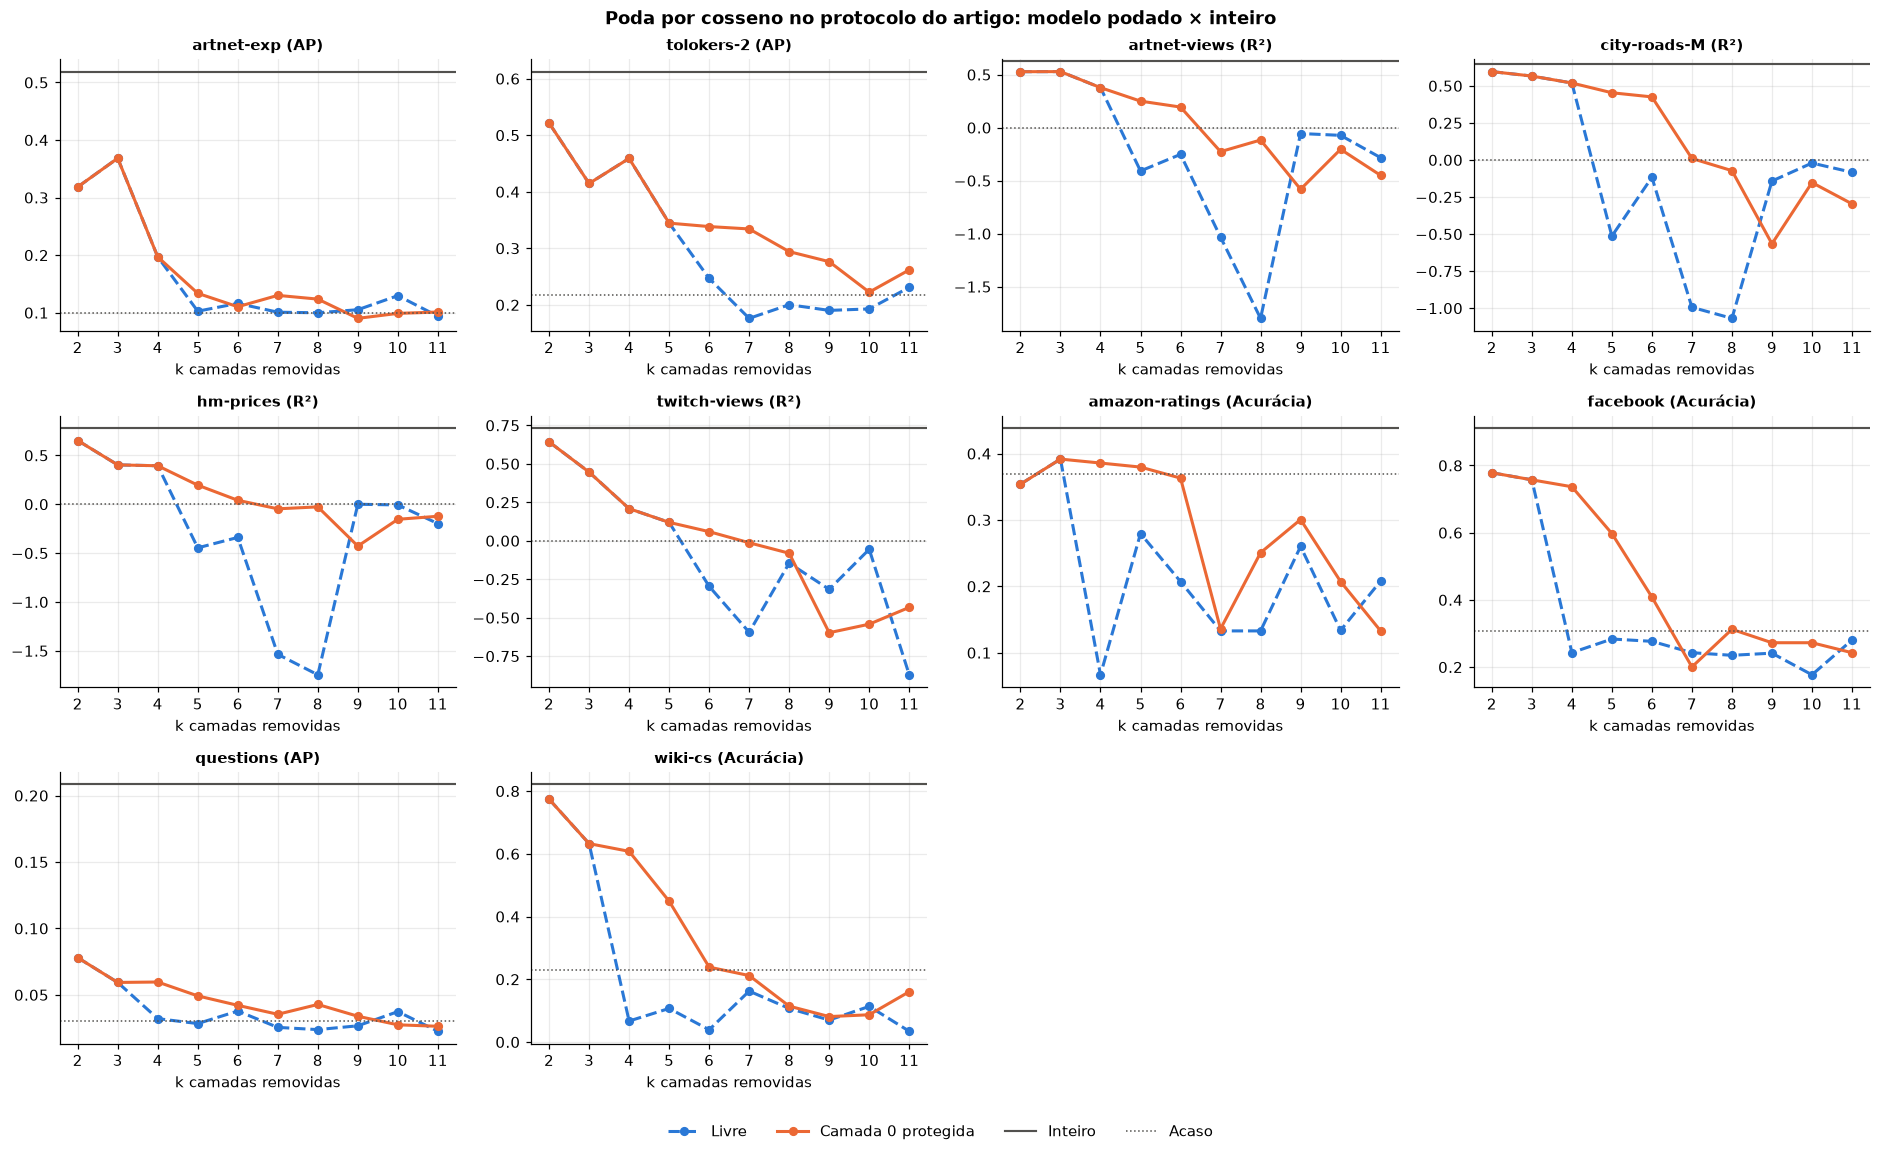

In [12]:
ncols = 4
nrows = int(np.ceil(len(TASKS) / ncols))
fig, axes = plt.subplots(nrows, ncols, figsize=(4.3 * ncols, 3.5 * nrows), squeeze=False)
for ax, n in zip(axes.flat, TASKS):
    m = f"test_{META[n]['metric']}"
    for j, v in enumerate(VARIANTS):
        r = RES[(n, v)]
        ax.plot(r.k[1:], r[m][1:], marker="o", color=COLORS[j], ls="-" if j else "--", label=v)
    ax.axhline(RES[(n, "Livre")][m].iloc[0], color=GRAY, lw=1.4, label="Inteiro")
    ax.axhline(META[n]["chance"], color=GRAY, ls=":", lw=1, label="Acaso")
    ax.set_title(f"{n} ({METRIC_LABEL[META[n]['metric']]})", fontsize=10)
    ax.set_xticks(K_LIST)
    ax.set_xlabel("k camadas removidas")
for ax in list(axes.flat)[len(TASKS):]:
    ax.axis("off")
handles, labels = axes.flat[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="lower center", ncol=4, frameon=False, bbox_to_anchor=(0.5, -0.01))
fig.suptitle("Poda por cosseno no protocolo do artigo: modelo podado × inteiro", fontweight="bold")
plt.tight_layout(rect=(0, 0.03, 1, 1))
plt.savefig(RESULTS_DIR / "metrica_artigo_todos.png", dpi=200, bbox_inches="tight")
plt.show()

## 6. Conclusões

Execução com 10 datasets × 3 sementes × ensemble de 10 membros (CSVs e figuras em `Block_Influence_results/graphfpn_poda_cosseno_artigo/`).

### 6.1 O modelo inteiro reproduz o artigo

| Dataset | Métrica | Inteiro (aqui) | Artigo, GraphPFN (ICL) |
|---|---|---|---|
| artnet-exp | AP | 0,519 | 0,518 |
| tolokers-2 | AP | 0,613 | 0,613 |
| artnet-views | R² | 0,629 | 0,628 |
| city-roads-M | R² | 0,649 | 0,649 |
| hm-prices | R² | 0,780 | 0,779 |
| twitch-views | R² | 0,733 | 0,732 |
| amazon-ratings | Acurácia | 0,439 | 0,449 |
| facebook | Acurácia | 0,911 | 0,924 |
| questions | AP | 0,208 | 0,214 |
| wiki-cs | Acurácia | 0,821 | 0,820 |

Os 6 datasets do GraphLand e o wiki-cs batem com o artigo até a 3ª casa. As diferenças em amazon-ratings, facebook e questions (≤ 0,013) vêm do split aleatório 10/10/80, que não é o mesmo sorteio do artigo, e, no facebook, das features reconstruídas por SVD.

**Fora da análise (não cabem em 16 GB mesmo com inferência em blocos):** city-reviews, avazu-ctr e pubmed.

### 6.2 Ordem de poda por BI

O ranking é praticamente o mesmo nos 10 datasets: as camadas **1 e 2** sempre têm o menor BI, seguidas de 3 e 4. A camada **0** aparece entre a 4ª e a 6ª posições. Por isso "poda 2 menores" remove as camadas {1, 2} em todos os datasets.

### 6.3 Métrica do artigo no teste: inteiro × podado

| Configuração | artnet-exp | tolokers-2 | artnet-views | city-roads-M | hm-prices | twitch-views | amazon-ratings | facebook | questions | wiki-cs |
|---|---|---|---|---|---|---|---|---|---|---|
| **Inteiro** | **0,519** | **0,612** | **0,629** | **0,649** | **0,780** | **0,733** | **0,439** | **0,911** | **0,208** | **0,821** |
| Poda 2 menores | 0,318 | 0,522 | 0,528 | 0,596 | 0,652 | 0,643 | 0,354 | 0,778 | 0,078 | 0,774 |
| Poda 3 menores | 0,368 | 0,415 | 0,529 | 0,566 | 0,403 | 0,446 | 0,392 | 0,757 | 0,059 | 0,633 |
| Poda 4, livre | 0,197 | 0,459 | 0,378 | 0,519 | 0,394 | 0,209 | 0,067 | 0,243 | 0,032 | 0,067 |
| Poda 4, camada 0 protegida | 0,197 | 0,459 | 0,378 | 0,519 | 0,394 | 0,209 | 0,386 | 0,737 | 0,060 | 0,608 |
| Poda 5, livre | 0,103 | 0,345 | −0,409 | −0,514 | −0,446 | 0,120 | 0,279 | 0,284 | 0,028 | 0,107 |
| Poda 5, camada 0 protegida | 0,134 | 0,345 | 0,250 | 0,453 | 0,195 | 0,120 | 0,380 | 0,598 | 0,049 | 0,449 |
| Poda 6, camada 0 protegida | 0,110 | 0,338 | 0,194 | 0,425 | 0,041 | 0,059 | 0,363 | 0,408 | 0,042 | 0,239 |
| *Acaso* | *0,100* | *0,218* | *0* | *0* | *0* | *0* | *0,369* | *0,306* | *0,030* | *0,230* |

1. **Nenhuma poda preserva o desempenho, já a partir de k = 2.** Removendo só as camadas 1 e 2 (−16% dos parâmetros), a queda vai de 0,05 (city-roads-M, wiki-cs) a 0,20 (artnet-exp). O questions perde 62% do AP (0,208 → 0,078), e o amazon-ratings já cai abaixo do acaso (0,354 contra 0,369).
2. **Com o protocolo do artigo, o padrão das análises anteriores se repete.** Na versão livre, o modelo colapsa assim que a camada 0 entra na lista de poda: k = 4 nos datasets clássicos (amazon-ratings, facebook, wiki-cs: acurácia → 0,07–0,24) e k = 5 nos de regressão (R² negativo).
3. **Proteger a camada 0 evita o colapso, mas não a perda.** Com a camada 0 protegida, o facebook mantém 0,737 com k = 4 (contra 0,243 na versão livre), o wiki-cs 0,608 (contra 0,067) e o city-roads-M R² 0,45 com k = 5 (contra −0,51). A queda continua grande e cresce com k; com k ≥ 7, os dois casos ficam perto ou abaixo do acaso.
4. **A sensibilidade varia muito entre datasets.** O city-roads-M é o mais tolerante (R² 0,649 → 0,519 removendo 4 camadas). O questions e o artnet-exp, ambos de classificação binária com poucos positivos, são os mais frágeis.
5. **Curvas não monótonas para k grande** (por exemplo, hm-prices R² −1,75 em k = 8 e −0,00 em k = 9) são ruído entre modelos já quebrados, não recuperação.

**Resumo:** no protocolo e nos datasets do artigo, remover camadas do GraphPFN por BI cosseno, sem re-treino, não é uma poda viável para nenhum k ≥ 2, com ou sem a camada 0 protegida. Para recuperar o desempenho é preciso re-treinar o modelo podado: o notebook `kd_podado_vs_aleatorio_graphpfn.ipynb` mostra que um KD curto recupera ~95% do desempenho do teacher partindo do modelo com 6 camadas.
